# R5 Variability-vs-Reward Recovery Curve, Over Time

The within-session "does variability recover with time since the last reward" analysis
from `session_variability.ipynb` (section 3c) / `multi_session_variability.ipynb`
(section 2), rerun on **every R5 session with >= 10 online-triggered rewards**
(`behavior_log.csv` `triggered==1`, the real online rule -- not the offline-replay
`is_matched` flag; threshold lowered from an earlier version's 20 to match the report-wide
10-reward standard), and broken into date chunks so the shape/magnitude of the recovery
curve can be compared across training and across the DLS lesion.

**Chunking:** the pre-lesion span (2026-06-11 .. 2026-09-08) is cut into ~2-week windows;
post-lesion is sessions on **2026-09-09 and later**, per instruction, kept as its own
window. Chunk edges are calendar dates, not session counts, so window sizes (in sessions)
vary -- shown in each panel title.

**Note:** at the 10-reward threshold, 2026_09_09_1 (19 rewards) now qualifies and is
included in the post-lesion window alongside 2026_09_10_1 and 2026_09_11_1 (no newer R5
sessions exist yet as of this run).

In [ ]:
import sys, os
sys.path.insert(0, '.')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scripts.build_variability_summary import discover_qualifying_sessions, parse_session_date
from clirb.native_dannce import build_session_variability

%matplotlib inline

RAT = 'R5'
MIN_REWARDS = 10

sessions = discover_qualifying_sessions([RAT])
print(f'{len(sessions)} R5 sessions with dual data + behavior log')

rows = []
session_summary = []
for rat, session in sessions:
    date = parse_session_date(session)
    try:
        d = build_session_variability(rat, session)
    except Exception as e:
        print(f'  {session}: FAILED -- {e!r}')
        continue
    session_summary.append((session, date, d['n_rewards'], d['n_valid']))
    if d['n_rewards'] < MIN_REWARDS:
        continue
    rsr = d['rears_since_reward']
    after = rsr >= 0
    for i in np.where(after)[0]:
        rows.append(dict(session=session, session_date=date, n_rewards_session=d['n_rewards'],
                         rears_since_reward=int(rsr[i]),
                         var_pc1=d['variability'][i, 0], var_pc2=d['variability'][i, 1],
                         var_pc3=d['variability'][i, 2]))

df = pd.DataFrame(rows)
qualifying_sessions = sorted(set(zip(df.session, df.session_date)), key=lambda x: x[1])
n_after_first_reward = len(df)
print(f'{len(qualifying_sessions)}/{len(session_summary)} sessions qualify '
     f'(>= {MIN_REWARDS} rewards), {n_after_first_reward} rears counted '
     f'(each session restricted to rears after its own first reward)')


In [2]:
CHUNKS = [
    ('Jun 11-24',            '2026-06-11', '2026-06-24'),
    ('Jun 25-Jul 8',         '2026-06-25', '2026-07-08'),
    ('Jul 9-22',             '2026-07-09', '2026-07-22'),
    ('Jul 23-Aug 5',         '2026-07-23', '2026-08-05'),
    ('Aug 6-19',             '2026-08-06', '2026-08-19'),
    ('Aug 20-Sep 8',         '2026-08-20', '2026-09-08'),
    ('Post-lesion (Sep 9+)', '2026-09-09', '2099-01-01'),
]

def assign_chunk(date):
    for label, lo, hi in CHUNKS:
        if lo <= date <= hi:
            return label
    return None

df['chunk'] = df['session_date'].map(assign_chunk)
assert df['chunk'].notna().all(), 'some rears fell outside all defined chunks'

print(f"{'chunk':24s} {'date range':24s} {'n sessions':>10s} {'n rears':>8s}")
for label, lo, hi in CHUNKS:
    sub = df[df.chunk == label]
    n_sess = sub['session'].nunique()
    print(f'{label:24s} {lo}..{hi:12s} {n_sess:10d} {len(sub):8d}')


chunk                    date range               n sessions  n rears
Jun 11-24                2026-06-11..2026-06-24           10     1424
Jun 25-Jul 8             2026-06-25..2026-07-08            9     1773
Jul 9-22                 2026-07-09..2026-07-22           12     1862
Jul 23-Aug 5             2026-07-23..2026-08-05            7     1389
Aug 6-19                 2026-08-06..2026-08-19            2      441
Aug 20-Sep 8             2026-08-20..2026-09-08            2      110
Post-lesion (Sep 9+)     2026-09-09..2099-01-01            2      346


## Variability vs. rears since last reward, by period

Each column is one date chunk (chronological, left to right; the last column is
post-lesion). Each row is a PC. Bins pool every qualifying session's rears within that
chunk. Raw units (not session-normalized) -- reasonable within a single rat/chunk since
template refits are relatively less frequent within a ~2-week window, but keep in mind
across chunks a template change could shift the scale (see the "Template evolution"
section of the published report for how much R5's own bounds have moved around).

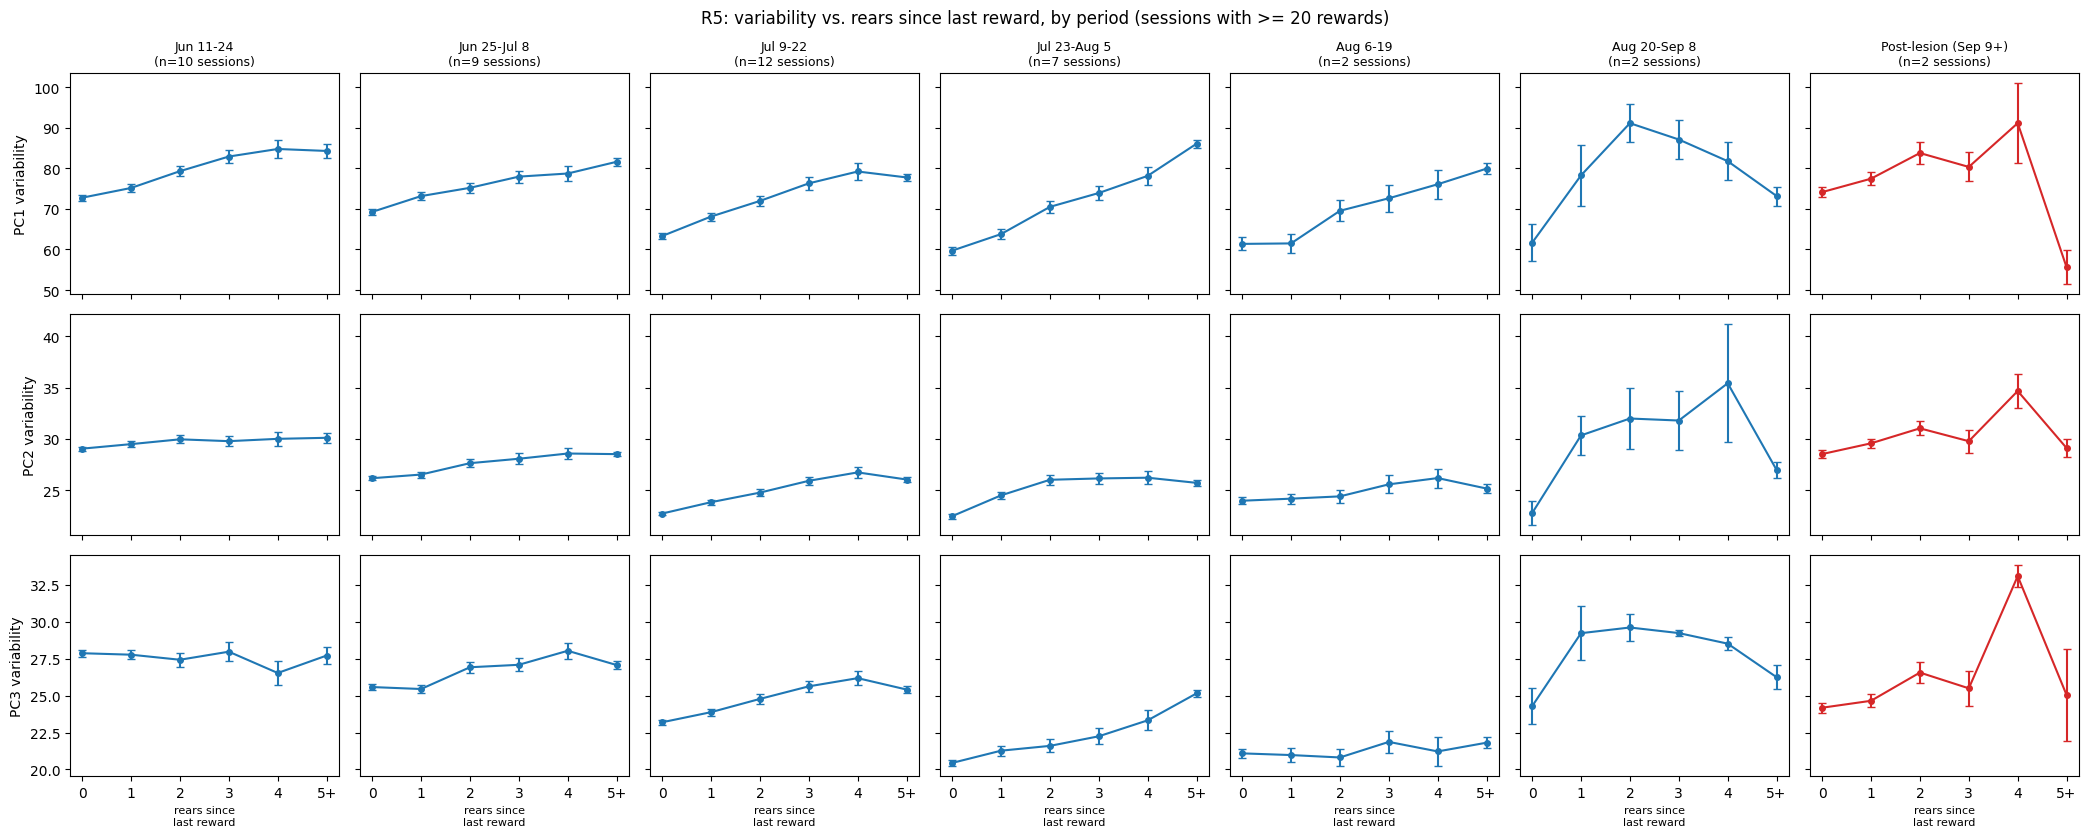

In [3]:
BIN_EDGES = [0, 1, 2, 3, 4, 5, np.inf]
BIN_LABELS = ['0', '1', '2', '3', '4', '5+']
N_PCS = 3
chunk_labels = [c[0] for c in CHUNKS if (df.chunk == c[0]).any()]
n_chunks = len(chunk_labels)

fig, axes = plt.subplots(N_PCS, n_chunks, figsize=(3.0 * n_chunks, 8.5),
                         sharex=True, sharey='row')
for col_i, label in enumerate(chunk_labels):
    sub = df[df.chunk == label]
    bin_idx = np.digitize(sub['rears_since_reward'], BIN_EDGES[1:-1], right=False)
    n_sess = sub['session'].nunique()
    is_post = label.startswith('Post-lesion')
    for pidx in range(N_PCS):
        ax = axes[pidx, col_i]
        col = f'var_pc{pidx + 1}'
        means, sems = [], []
        for b in range(len(BIN_LABELS)):
            vals = sub[col][bin_idx == b]
            means.append(vals.mean() if len(vals) else np.nan)
            sems.append(vals.std(ddof=1) / np.sqrt(len(vals)) if len(vals) > 1 else 0.0)
        xs = np.arange(len(BIN_LABELS))
        ax.errorbar(xs, means, yerr=sems, marker='o', ms=4, capsize=3,
                   color='#d62728' if is_post else '#1f77b4')
        if pidx == 0:
            ax.set_title(f'{label}\n(n={n_sess} sessions)', fontsize=9)
        if col_i == 0:
            ax.set_ylabel(f'PC{pidx + 1} variability')
        if pidx == N_PCS - 1:
            ax.set_xticks(xs); ax.set_xticklabels(BIN_LABELS)
            ax.set_xlabel('rears since\nlast reward', fontsize=8)
fig.suptitle(f'{RAT}: variability vs. rears since last reward, by period '
            f'(sessions with >= {MIN_REWARDS} rewards)', fontsize=12)
fig.tight_layout()
plt.show()
